In [1]:
from datasets import load_dataset
import pandas as pd

ds = load_dataset("coastalcph/lex_glue", "ledgar")
label_names = ds["train"].features["label"].names

train = pd.DataFrame(ds["train"])
val = pd.DataFrame(ds["validation"])
test = pd.DataFrame(ds["test"])

print(train.shape, val.shape, test.shape)

README.md:   0%|          | 0.00/34.1k [00:00<?, ?B/s]

ledgar/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.9MB            

ledgar/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ledgar/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.31MB            

ledgar/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

ledgar/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/60000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10000 [00:00<?, ? examples/s]

(60000, 2) (10000, 2) (10000, 2)


In [2]:
train["label_name"] = train["label"].map(lambda i: label_names[i])
print(train["label_name"].value_counts().to_string())

label_name
Governing Laws                  3167
Notices                         2493
Counterparts                    2427
Entire Agreements               2340
Severability                    1808
Survival                        1469
Amendments                      1467
Assignments                     1327
Expenses                        1224
Terms                           1166
Terminations                    1112
Insurances                      1104
Taxes                           1089
Litigations                     1034
Confidentiality                 1012
Further Assurances              1009
General                          976
Compliance With Laws             960
Indemnifications                 936
Waivers                          878
Use Of Proceeds                  866
Payments                         856
Waiver Of Jury Trials            768
No Conflicts                     741
Financial Statements             677
Remedies                         664
Base Salary                

In [3]:
print(train["text"].str.split().str.len().describe())
train.sample(3, random_state=1)[["text", "label_name"]]

count    60000.000000
mean       113.904267
std         96.265631
min          3.000000
25%         48.000000
50%         86.000000
75%        148.000000
max       1215.000000
Name: text, dtype: float64


,text,label_name
15281,"During the term of this Agreement, the Company...",Base Salary
21435,Each of the Company and its Subsidiaries has (...,Taxes
44536,This Agreement may be terminated by any Purcha...,Terminations


In [4]:
print(label_names)

['Adjustments', 'Agreements', 'Amendments', 'Anti-Corruption Laws', 'Applicable Laws', 'Approvals', 'Arbitration', 'Assignments', 'Assigns', 'Authority', 'Authorizations', 'Base Salary', 'Benefits', 'Binding Effects', 'Books', 'Brokers', 'Capitalization', 'Change In Control', 'Closings', 'Compliance With Laws', 'Confidentiality', 'Consent To Jurisdiction', 'Consents', 'Construction', 'Cooperation', 'Costs', 'Counterparts', 'Death', 'Defined Terms', 'Definitions', 'Disability', 'Disclosures', 'Duties', 'Effective Dates', 'Effectiveness', 'Employment', 'Enforceability', 'Enforcements', 'Entire Agreements', 'Erisa', 'Existence', 'Expenses', 'Fees', 'Financial Statements', 'Forfeitures', 'Further Assurances', 'General', 'Governing Laws', 'Headings', 'Indemnifications', 'Indemnity', 'Insurances', 'Integration', 'Intellectual Property', 'Interests', 'Interpretations', 'Jurisdictions', 'Liens', 'Litigations', 'Miscellaneous', 'Modifications', 'No Conflicts', 'No Defaults', 'No Waivers', 'Non-

In [5]:
HIGH = [
    "Anti-Corruption Laws", "Arbitration", "Change In Control", "Compliance With Laws",
    "Confidentiality", "Consent To Jurisdiction", "Erisa", "Forfeitures",
    "Indemnifications", "Indemnity", "Intellectual Property", "Liens", "Litigations",
    "Releases", "Remedies", "Representations", "Sanctions", "Solvency",
    "Specific Performance", "Submission To Jurisdiction", "Tax Withholdings", "Taxes",
    "Terminations", "Waiver Of Jury Trials", "Warranties", "Withholdings",
]

LOW = [
    "Assigns", "Binding Effects", "Books", "Construction", "Cooperation", "Counterparts",
    "Defined Terms", "Definitions", "Duties", "Effective Dates", "Effectiveness",
    "Entire Agreements", "Existence", "Further Assurances", "General", "Headings",
    "Integration", "Interpretations", "Miscellaneous", "Notices", "Organizations",
    "Positions", "Publicity", "Qualifications", "Records", "Severability",
    "Successors", "Titles", "Vacations",
]

risk_map = {}
for name in label_names:
    if name in HIGH:
        risk_map[name] = "High"
    elif name in LOW:
        risk_map[name] = "Low"
    else:
        risk_map[name] = "Medium"

# sanity check: every listed name must exist in the dataset
assert all(n in label_names for n in HIGH + LOW), "A name doesn't match label_names"

for df in (train, val, test):
    df["label_name"] = df["label"].map(lambda i: label_names[i])
    df["risk"] = df["label_name"].map(risk_map)

print(train["risk"].value_counts())
print(train["risk"].value_counts(normalize=True).round(3))

risk
Medium    27077
Low       18965
High      13958
Name: count, dtype: int64
risk
Medium    0.451
Low       0.316
High      0.233
Name: proportion, dtype: float64


In [6]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

def clean_text(t):
    t = t.lower()
    t = re.sub(r"\s+", " ", t)
    return t.strip()

for df in (train, val, test):
    df["clean"] = df["text"].map(clean_text)

vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=50000, sublinear_tf=True)
X_train = vec.fit_transform(train["clean"])
X_val = vec.transform(val["clean"])

clf = LogisticRegression(max_iter=1000, C=5)
clf.fit(X_train, train["risk"])

pred = clf.predict(X_val)
print(classification_report(val["risk"], pred, digits=3))

              precision    recall  f1-score   support

        High      0.927     0.921     0.924      2343
         Low      0.950     0.937     0.943      3197
      Medium      0.931     0.943     0.937      4460

    accuracy                          0.936     10000
   macro avg      0.936     0.934     0.935     10000
weighted avg      0.936     0.936     0.936     10000



In [7]:
import numpy as np
import pandas as pd

proba = clf.predict_proba(X_val)
conf = proba.max(axis=1)
pred = clf.classes_[proba.argmax(axis=1)]
y_val = val["risk"].values

rows = []
for t in [0.5, 0.6, 0.7, 0.8, 0.9]:
    auto = conf >= t
    rows.append({
        "threshold": t,
        "auto_labeled_%": round(auto.mean() * 100, 1),
        "sent_to_review_%": round((~auto).mean() * 100, 1),
        "accuracy_on_auto_%": round((pred[auto] == y_val[auto]).mean() * 100, 1),
        "accuracy_on_review_%": round((pred[~auto] == y_val[~auto]).mean() * 100, 1),
    })

print(pd.DataFrame(rows).to_string(index=False))

 threshold  auto_labeled_%  sent_to_review_%  accuracy_on_auto_%  accuracy_on_review_%
       0.5            98.4               1.6                94.4                  47.3
       0.6            94.9               5.1                95.5                  58.0
       0.7            90.9               9.1                96.7                  62.9
       0.8            85.3              14.7                97.6                  70.2
       0.9            75.4              24.6                98.6                  78.5


In [8]:
from sklearn.metrics.pairwise import cosine_similarity

THRESHOLD = 0.8
feature_names = np.array(vec.get_feature_names_out())
classes = list(clf.classes_)

def analyze(text, top_terms=6, n_similar=3):
    clean = clean_text(text)
    x = vec.transform([clean])
    p = clf.predict_proba(x)[0]
    idx = p.argmax()
    label, confidence = classes[idx], p[idx]

    # top terms: tfidf value * model weight for the predicted class
    contrib = x.toarray()[0] * clf.coef_[idx]
    top = np.argsort(contrib)[::-1][:top_terms]
    terms = [feature_names[i] for i in top if contrib[i] > 0]

    # nearest similar clauses from training data
    sims = cosine_similarity(x, X_train)[0]
    nn = np.argsort(sims)[::-1][:n_similar]
    similar = train.iloc[nn][["text", "label_name", "risk"]].copy()
    similar["similarity"] = sims[nn].round(3)

    return {
        "risk": label,
        "confidence": round(float(confidence), 3),
        "needs_review": bool(confidence < THRESHOLD),
        "top_terms": terms,
        "similar": similar,
    }

# try it on a few validation clauses
for i in [0, 1, 2]:
    r = analyze(val.iloc[i]["text"])
    print("TEXT:", val.iloc[i]["text"][:200])
    print("TRUE:", val.iloc[i]["risk"], "| PRED:", r["risk"], r["confidence"],
          "| REVIEW:", r["needs_review"])
    print("TERMS:", r["top_terms"])
    print(r["similar"][["label_name", "risk", "similarity"]].to_string(index=False))
    print("-" * 60)

TEXT: This Agreement may be amended from time to time by the Committee in its discretion; provided , however , that this Agreement may not be modified in a manner that would have an adverse effect on the Aw
TRUE: Medium | PRED: Medium 0.987 | REVIEW: False
TERMS: ['be amended', 'document signed', 'discretion', 'written document', 'signed by', 'amended']
label_name   risk  similarity
Amendments Medium       0.939
Amendments Medium       0.899
Amendments Medium       0.861
------------------------------------------------------------
TEXT: This Agreement embodies the entire agreement between the parties and supersedes all prior agreements and understandings relating to the Property except for any confidentiality agreement binding on Pur
TRUE: Medium | PRED: Low 0.99 | REVIEW: False
TERMS: ['entire agreement', 'the entire', 'entire', 'supersedes', 'understandings', 'binding']
       label_name   risk  similarity
       Amendments Medium       0.438
Entire Agreements    Low       0.426
    

=== All test clauses ===
              precision    recall  f1-score   support

        High      0.916     0.923     0.920      2215
         Low      0.951     0.922     0.936      3522
      Medium      0.917     0.937     0.927      4263

    accuracy                          0.929     10000
   macro avg      0.928     0.927     0.928     10000
weighted avg      0.929     0.929     0.929     10000

=== Auto-labeled only (confidence >= 0.8) ===
Share auto-labeled: 85.8%  |  Sent to review: 14.2%
              precision    recall  f1-score   support

        High      0.966     0.973     0.969      1820
         Low      0.976     0.970     0.973      3062
      Medium      0.967     0.969     0.968      3694

    accuracy                          0.970      8576
   macro avg      0.970     0.971     0.970      8576
weighted avg      0.970     0.970     0.970      8576



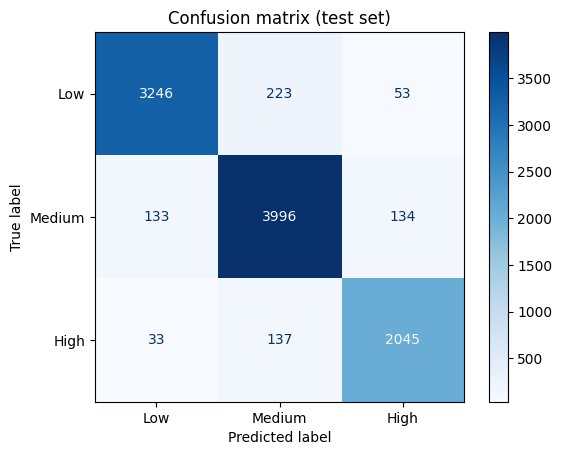

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

X_test = vec.transform(test["clean"])
proba_t = clf.predict_proba(X_test)
conf_t = proba_t.max(axis=1)
pred_t = clf.classes_[proba_t.argmax(axis=1)]
y_test = test["risk"].values
auto = conf_t >= THRESHOLD

print("=== All test clauses ===")
print(classification_report(y_test, pred_t, digits=3))

print(f"=== Auto-labeled only (confidence >= {THRESHOLD}) ===")
print(f"Share auto-labeled: {auto.mean()*100:.1f}%  |  Sent to review: {(~auto).mean()*100:.1f}%")
print(classification_report(y_test[auto], pred_t[auto], digits=3))

labels = ["Low", "Medium", "High"]
cm = confusion_matrix(y_test, pred_t, labels=labels)
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix (test set)")
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
import joblib
from google.colab import files

joblib.dump({"vec": vec, "clf": clf, "risk_map": risk_map, "threshold": THRESHOLD},
            "risk_model.joblib")
files.download("risk_model.joblib")
files.download("confusion_matrix.png")

In [10]:
import sklearn, joblib
from google.colab import files

print("scikit-learn version:", sklearn.__version__)

joblib.dump({
    "vec": vec,
    "clf": clf,
    "risk_map": risk_map,
    "threshold": THRESHOLD,
    "X_train": X_train,
    "train_text": train["text"].tolist(),
    "train_label": train["label_name"].tolist(),
    "train_risk": train["risk"].tolist(),
}, "risk_model.joblib", compress=3)

files.download("risk_model.joblib")
files.download("confusion_matrix.png")

scikit-learn version: 1.6.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>